# 02. Limpieza y preparación

Decisiones de preprocesamiento, construcción del historial **sin fuga temporal** y partición **por paciente**.

In [1]:
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import cargar_config, ruta, guardar_json, leer_json
CFG = cargar_config()
FIG = ruta(CFG["rutas"]["figuras"]); MET = ruta(CFG["rutas"]["metricas"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C1, C2, C3, C4 = "#1F3A5F", "#C0504D", "#7F7F7F", "#E1A93B"
def guardar(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, bbox_inches="tight"); plt.show()
from src.data_processing import cargar_crudos, limpiar, agregar_historial, particionar_por_paciente, FEATURES

In [2]:
crudo = cargar_crudos(CFG['rutas']['datos_crudos'])
df = limpiar(crudo)
print('filas tras limpieza:', len(df))

2026-09-26 02:32:15 | INFO | priorizacion | datos crudos cargados: 110527 filas


2026-09-26 02:32:16 | INFO | priorizacion | limpieza: 1 edades negativas eliminadas, 5 antelaciones negativas llevadas a 0


filas tras limpieza: 110526


## Historial sin fuga temporal
Una cita solo usa el desenlace de citas **ya atendidas** cuando se agendó. Ejemplo con un paciente real con varias citas:

In [3]:
df = agregar_historial(df)
pac = df.PatientId.value_counts().index[5]
df[df.PatientId==pac].sort_values('ScheduledDay')[['ScheduledDay','AppointmentDay','no_show','prior_appts','prior_noshow_rate']].head(8)

,ScheduledDay,AppointmentDay,no_show,prior_appts,prior_noshow_rate
25410,2016-04-27 17:23:28,2016-05-04,0,0,0.0
28979,2016-04-29 07:33:46,2016-05-13,1,0,0.0
3051,2016-04-29 08:42:11,2016-04-29,0,0,0.0
31612,2016-04-29 11:51:04,2016-05-04,1,0,0.0
3062,2016-04-29 12:10:15,2016-04-29,0,0,0.0
3109,2016-04-29 17:11:18,2016-04-29,0,0,0.0
35669,2016-05-02 17:56:59,2016-05-02,0,3,0.0
7510,2016-05-03 14:37:41,2016-05-03,0,4,0.0


In [4]:
print('Citas con historial disponible:', f"{(df.prior_appts>0).mean():.1%}")
print('Mediana de citas previas entre quienes tienen historial:', df.loc[df.prior_appts>0,'prior_appts'].median())

Citas con historial disponible: 27.9%
Mediana de citas previas entre quienes tienen historial: 1.0


## Partición por paciente (75/25)
`StratifiedGroupKFold` garantiza que ningún paciente esté en entrenamiento y prueba a la vez. La frecuencia del barrio se calcula solo con entrenamiento.

In [5]:
train, test, freq = particionar_por_paciente(df, CFG['particion']['pliegues_particion'], CFG['proyecto']['semilla'])
resumen = pd.DataFrame({'citas':[len(train),len(test)], 'pacientes':[train.PatientId.nunique(), test.PatientId.nunique()],
    'tasa_no_show':[train.no_show.mean(), test.no_show.mean()]}, index=['entrenamiento','prueba']).round(4)
print('pacientes en ambos:', len(set(train.PatientId) & set(test.PatientId))); resumen

2026-09-26 02:32:33 | INFO | priorizacion | partición por paciente: 82895 entrenamiento, 27631 prueba


pacientes en ambos: 0


,citas,pacientes,tasa_no_show
entrenamiento,82895,46636,0.2019
prueba,27631,15662,0.2019


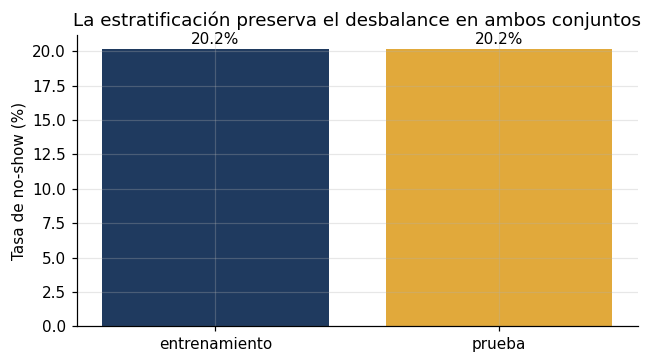

In [6]:
fig, ax = plt.subplots(figsize=(6,3.4)); ax.bar(resumen.index, 100*resumen.tasa_no_show, color=[C1,C4])
for i,v in enumerate(resumen.tasa_no_show): ax.text(i, 100*v+0.3, f'{100*v:.1f}%', ha='center')
ax.set_ylabel('Tasa de no-show (%)'); ax.set_title('La estratificación preserva el desbalance en ambos conjuntos')
guardar('08_particion.png')

## Manejo del desbalance
No se usa sobremuestreo ni ponderación de clases, porque distorsionan las probabilidades que el sistema usa para priorizar. El desbalance se maneja con métricas adecuadas (AUC-PR, Brier) y con la elección explícita del umbral (notebook 04).

In [7]:
procesado = pd.concat([train.assign(conjunto='entrenamiento'), test.assign(conjunto='prueba')])
cols = ['PatientId','AppointmentID','Neighbourhood','no_show','conjunto'] + FEATURES
procesado[cols].to_csv(ruta(CFG['rutas']['datos_procesados']), index=False)
guardar_json(freq, CFG['rutas']['frecuencia_barrios'])
print('guardado:', CFG['rutas']['datos_procesados'], procesado[cols].shape)

guardado: data/processed/citas_procesadas.csv (110526, 19)
